# Spoken command recognition from scratch - JarvisTEC (`speech_commands`)

**Team members:** Anthony Jafeth Arias Robleto (2020007243), Randy Espinoza Downing (2021031263), Kenneth Jhoan Araya Arguedas (2024177221)
**Dataset:** [Speech Commands v0.02](https://www.tensorflow.org/datasets/catalog/speech_commands) (Warden, 2018), Google, CC BY 4.0: 105 829 one-second recordings of 35 English words spoken by 2 618 people.

A convolutional neural network trained **from random initialization** to recognize spoken words from audio. It is the project's own speech engine, an alternative to the pretrained recognizers the application also offers (the browser's and Vosk). Speech Commands contains single words, not the JarvisTEC phrases, so this model recognizes the **number of a model**: "JarvisTEC... three" runs model 3. It is a keyword spotter, not a general speech-to-text system.

| Section | Points |
|---|---|
| 1. Problem analysis | 0.5 |
| 2. Data understanding | 0.5 |
| 3. Data exploration | 0.5 |
| 4. Model | 2 |
| 5. Evaluation | 1 |
| 6. Conclusion | 0.5 |

## Configuration

In [1]:
import json
import random
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import soundfile
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import display
from sklearn import metrics

warnings.filterwarnings("ignore")

MODEL_NAME = "speech_commands"
DATA_DIR = Path("../../data/speech_commands")
ARTIFACTS = Path("../../artifacts")
# One JSON line per epoch, to follow the training while it runs
# (data/ is git-ignored).
PROGRESS = Path("../../data/training_progress") / f"{MODEL_NAME}.jsonl"
# The ten digits are the commands: the digit of a model runs it.
DIGITS = ["zero", "one", "two", "three", "four", "five", "six", "seven", "eight", "nine"]
CLASSES = DIGITS + ["unknown", "silence"]
SAMPLE_RATE = 16000
CLIP_SAMPLES = SAMPLE_RATE  # one second
# Log-mel features: 25 ms windows every 10 ms, 40 mel bands.
WINDOW, HOP, N_FFT, N_MELS = 400, 160, 512, 40
# Unknown words and silence clips kept in training, relative to the size
# of an average digit class.
UNKNOWN_RATIO, SILENCE_RATIO = 2.0, 1.0
# Training clips of the other 25 words kept in memory (out of about 60 000).
UNKNOWN_POOL = 15000
EPOCHS = 40
BATCH_SIZE = 256
LEARNING_RATE = 3e-3
WEIGHT_DECAY = 1e-3
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch", torch.__version__, "on", DEVICE,
      torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")

PyTorch 2.14.1+cu130 on cuda NVIDIA GeForce RTX 5060


## 1. Problem analysis

JarvisTEC is driven by voice. The pretrained engines it offers turn any sentence into text; this model is the project's own engine, trained from scratch, for a narrower task: **recognize which of the ten models the user asks for**, by its number, and ignore everything else.

- **Task type:** multiclass audio classification, 12 classes: the ten digits (*zero* to *nine*), **unknown** (any other word) and **silence** (background noise). This is the standard keyword-spotting formulation of Speech Commands (Warden, 2018).
- **Why a convolutional network on log-mel spectrograms:** a spectrogram turns sound into a time-frequency image, and small CNNs on it are the reference approach for keyword spotting with limited compute (Sainath & Parada, 2015).
- **Success metrics:** **accuracy** (the standard metric of the dataset) and **macro F1**. In the application, a word must not be mistaken for a command, so the precision of the digit classes (how often a detected digit is really that digit) is also reported.
- **Baselines:** the most frequent class, and logistic regression on the average spectrum of each clip (a model that ignores how the sound changes over time).
- **Use in the application:** the user says the wake word and the number ("JarvisTEC, three"); a one-second window slides over the recording and the most confident digit is taken (section 5 evaluates that procedure too).

## 2. Data understanding

In [2]:
words = sorted(p.name for p in DATA_DIR.iterdir() if p.is_dir() and not p.name.startswith("_"))
validation_list = set((DATA_DIR / "validation_list.txt").read_text().split())
testing_list = set((DATA_DIR / "testing_list.txt").read_text().split())
rows = []
for word in words:
    for path in (DATA_DIR / word).glob("*.wav"):
        relative = f"{word}/{path.name}"
        split = "test" if relative in testing_list else "validation" if relative in validation_list else "train"
        rows.append({"path": relative, "word": word, "speaker": path.name.split("_")[0], "split": split})
files = pd.DataFrame(rows)
print(len(words), "words,", len(files), "clips,", files.speaker.nunique(), "speakers")
display(files.groupby("split").agg(clips=("path", "size"), speakers=("speaker", "nunique")))
shared = set(files[files.split == "train"].speaker) & set(files[files.split == "test"].speaker)
print("Speakers in both train and test:", len(shared))

35 words, 105829 clips, 2618 speakers


,clips,speakers
split,,
test,11005,250
train,84843,2112
validation,9981,256


Speakers in both train and test: 0


In [3]:
per_word = files.pivot_table(index="word", columns="split", values="path", aggfunc="size")
per_word["is a command"] = per_word.index.isin(DIGITS)
display(per_word.sort_values("train", ascending=False))

split,test,train,validation,is a command
word,,,,
zero,418,3250,384,True
five,445,3240,367,True
yes,419,3228,397,False
seven,406,3205,387,True
nine,408,3170,356,True
one,399,3140,351,True
down,406,3134,377,False
no,405,3130,406,False
two,424,3111,345,True


In [4]:
def read_clip(relative):
    samples, rate = soundfile.read(DATA_DIR / relative, dtype="int16")
    assert rate == SAMPLE_RATE
    return samples


durations = np.array([len(read_clip(p)) for p in files.sample(2000, random_state=SEED).path]) / SAMPLE_RATE
print(f"Duration of 2000 random clips: min {durations.min():.2f} s, "
      f"{(durations < 1).mean() * 100:.1f} % shorter than 1 s (they are padded with zeros)")
noise_files = sorted((DATA_DIR / "_background_noise_").glob("*.wav"))
for path in noise_files:
    info = soundfile.info(path)
    print(f"background noise: {path.name} ({info.duration:.0f} s)")

Duration of 2000 random clips: min 0.42 s, 9.3 % shorter than 1 s (they are padded with zeros)
background noise: doing_the_dishes.wav (95 s)
background noise: dude_miaowing.wav (62 s)
background noise: exercise_bike.wav (61 s)
background noise: pink_noise.wav (60 s)
background noise: running_tap.wav (61 s)
background noise: white_noise.wav (60 s)


Speech Commands v0.02 has 105 829 WAV clips (16 kHz, mono, 16-bit) of at most one second, each with one of 35 words, recorded by 2 618 volunteers with their own phones and computers, so the microphones, rooms and accents vary a lot. The dataset defines its own validation and test lists, built by hashing the speaker ID, so **no speaker appears in two splits** (the output above confirms it); the test result therefore measures how the model works with voices it has never heard. It also includes six longer background noise recordings (white and pink noise, a running tap, an exercise bike, dishes), used here to build the silence class and to add noise to the training clips. Some clips are shorter than one second and are padded with zeros.

## 3. Data exploration

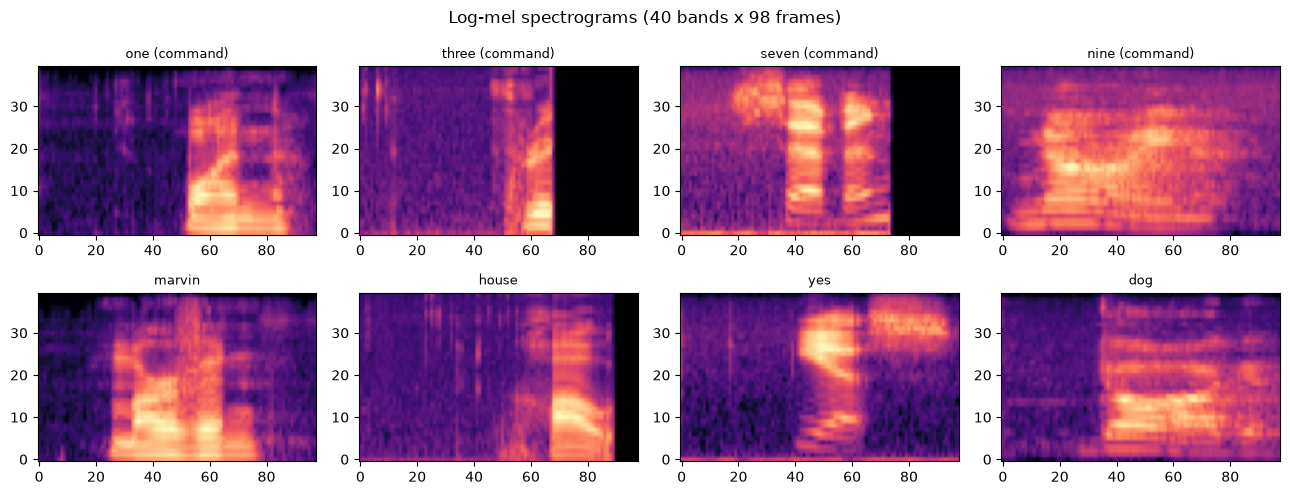

In [5]:
def mel_filterbank():
    """Triangular mel filters (HTK formula), shape (N_MELS, N_FFT // 2 + 1)."""
    def to_mel(hz):
        return 2595 * np.log10(1 + hz / 700)

    def to_hz(mel):
        return 700 * (10 ** (mel / 2595) - 1)

    edges = to_hz(np.linspace(to_mel(20), to_mel(SAMPLE_RATE / 2), N_MELS + 2))
    bins = np.fft.rfftfreq(N_FFT, 1 / SAMPLE_RATE)
    bank = np.zeros((N_MELS, len(bins)), np.float32)
    for m in range(N_MELS):
        left, center, right = edges[m], edges[m + 1], edges[m + 2]
        rising = (bins - left) / (center - left)
        falling = (right - bins) / (right - center)
        bank[m] = np.maximum(0, np.minimum(rising, falling))
    return bank


MEL = mel_filterbank()
HANN = (0.5 - 0.5 * np.cos(2 * np.pi * np.arange(WINDOW) / WINDOW)).astype(np.float32)


def log_mel(samples):
    """Log-mel spectrogram of one second of audio (float, -1..1).

    The backend computes exactly the same features with numpy
    (backend/services/speech_service.py); keep both identical.
    """
    count = 1 + (len(samples) - WINDOW) // HOP
    index = np.arange(WINDOW)[None] + HOP * np.arange(count)[:, None]
    spectrum = np.abs(np.fft.rfft(samples[index] * HANN, N_FFT)) ** 2
    return np.log(spectrum @ MEL.T + 1e-6).T.astype(np.float32)


def pad(samples):
    out = np.zeros(CLIP_SAMPLES, np.int16)
    out[:min(len(samples), CLIP_SAMPLES)] = samples[:CLIP_SAMPLES]
    return out


fig, axes = plt.subplots(2, 4, figsize=(13, 5))
examples = ["one", "three", "seven", "nine", "marvin", "house", "yes", "dog"]
for ax, word in zip(axes.ravel(), examples):
    clip = pad(read_clip(files[files.word == word].path.iloc[0])) / 32768
    ax.imshow(log_mel(clip), origin="lower", aspect="auto", cmap="magma")
    ax.set_title(word + (" (command)" if word in DIGITS else ""), fontsize=9)
plt.suptitle("Log-mel spectrograms (40 bands x 98 frames)")
plt.tight_layout()
plt.show()

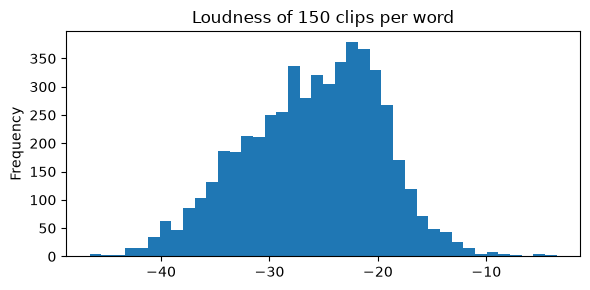

Loudness range (5th-95th percentile): -37 to -17 dB


In [6]:
sample = files.groupby("word").head(150)
loudness = []
for row in sample.itertuples():
    clip = read_clip(row.path).astype(np.float32) / 32768
    loudness.append({"word": row.word, "rms dB": 20 * np.log10(np.sqrt((clip ** 2).mean()) + 1e-9)})
loudness = pd.DataFrame(loudness)
loudness["rms dB"].plot(kind="hist", bins=40, figsize=(6, 3), title="Loudness of 150 clips per word")
plt.tight_layout()
plt.show()
print(f"Loudness range (5th-95th percentile): {loudness['rms dB'].quantile(0.05):.0f} to {loudness['rms dB'].quantile(0.95):.0f} dB")

- **Each word has its own pattern** in the spectrogram (the vowels are the bright horizontal bands, the consonants the short vertical bursts), and similar words look similar ("three" and "tree" are both in the dataset), which is why the unknown words matter: the model must learn to reject them.
- **Balance:** the ten digits have about 3 000 training clips each; the other 25 words together have about 60 000. Training on all of them would make "unknown" dominate, so they are **subsampled to twice the size of an average digit class** (redrawn every epoch, so all of them are eventually seen), and as many silence clips are cut from the background noise.
- **Loudness varies by more than 30 dB** between recordings (distance to the microphone, device gain), so the training clips are randomly scaled, and the features are standardized with the mean and standard deviation of the training set.
- **Noise and position:** recordings at home include noise and the word is not always centered, so training mixes in background noise and shifts the clips up to 100 ms in time; SpecAugment (Park et al., 2019) also masks random time and frequency bands.

## 4. Model

Clips are loaded into memory as 16-bit samples. Only what is used is loaded: every digit clip, and a fixed random pool of `UNKNOWN_POOL` training clips of the other 25 words (each epoch draws its unknown words from this pool). Validation and test keep every digit and a random sample of unknown words of twice the size of an average digit class, so the metrics are not dominated by the 25 other words. The official validation list chooses the best epoch; the official test list is used once, in section 5.

In [7]:
LABEL = {word: (CLASSES.index(word) if word in DIGITS else CLASSES.index("unknown")) for word in words}
UNKNOWN, SILENCE = CLASSES.index("unknown"), CLASSES.index("silence")


def load(split):
    part = files[files.split == split]
    digits = part[part.word.isin(DIGITS)]
    others = part[~part.word.isin(DIGITS)]
    size = UNKNOWN_POOL if split == "train" else int(len(digits) / len(DIGITS) * UNKNOWN_RATIO)
    part = pd.concat([digits, others.sample(size, random_state=SEED)])
    audio = np.stack([pad(read_clip(p)) for p in part.path])
    return audio, part.word.map(LABEL).to_numpy(), part.word.to_numpy()


start = time.time()
A_train, y_train_words, w_train = load("train")
A_val, y_val, w_val = load("validation")
A_test, y_test, w_test = load("test")
print(f"Loaded in {time.time() - start:.0f} s:", A_train.shape, A_val.shape, A_test.shape)

noises = [soundfile.read(p, dtype="float32")[0] for p in noise_files]
rng = np.random.default_rng(SEED)


def silence_clips(count):
    clips = []
    for _ in range(count):
        noise = noises[rng.integers(len(noises))]
        begin = rng.integers(len(noise) - CLIP_SAMPLES)
        clips.append(noise[begin:begin + CLIP_SAMPLES] * rng.uniform(0, 0.5))
    return (np.stack(clips) * 32767).astype(np.int16)


digit_average = int(np.mean([np.sum(y_train_words == i) for i in range(len(DIGITS))]))
n_silence = int(digit_average * SILENCE_RATIO)
n_unknown = int(digit_average * UNKNOWN_RATIO)
# Validation and test also get silence clips, in the same proportion as the test digits.
val_silence = silence_clips(int(np.mean([np.sum(y_val == i) for i in range(10)])))
test_silence = silence_clips(int(np.mean([np.sum(y_test == i) for i in range(10)])))
A_val = np.concatenate([A_val, val_silence]); y_val = np.concatenate([y_val, np.full(len(val_silence), SILENCE)])
A_test = np.concatenate([A_test, test_silence]); y_test = np.concatenate([y_test, np.full(len(test_silence), SILENCE)])
print("per training epoch:", digit_average, "clips per digit (average),", n_unknown, "unknown,", n_silence, "silence")
display(pd.DataFrame({"validation": np.bincount(y_val, minlength=12), "test": np.bincount(y_test, minlength=12)}, index=CLASSES).T)

Loaded in 190 s: (46158, 16000) (4371, 16000) (4928, 16000)
per training epoch: 3115 clips per digit (average), 6230 unknown, 3115 silence


,zero,one,two,three,four,five,six,seven,eight,nine,unknown,silence
validation,384,351,345,356,373,367,378,387,346,356,728,364
test,418,399,424,405,400,445,394,406,408,408,821,410


### Baselines

1. **Most frequent class.**
2. **Average spectrum + logistic regression:** the mean and standard deviation of every mel band over the second (80 numbers per clip). It knows which frequencies are present but not their order in time.

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


def summary_features(audio):
    feats = np.stack([log_mel(a.astype(np.float32) / 32768) for a in audio])
    return np.concatenate([feats.mean(axis=2), feats.std(axis=2)], axis=1)


baseline_rng = np.random.default_rng(SEED)
digits_index = np.flatnonzero(y_train_words != UNKNOWN)
unknown_index = baseline_rng.choice(np.flatnonzero(y_train_words == UNKNOWN), n_unknown, replace=False)
base_audio = np.concatenate([A_train[digits_index], A_train[unknown_index], silence_clips(n_silence)])
base_labels = np.concatenate([y_train_words[digits_index], y_train_words[unknown_index], np.full(n_silence, SILENCE)])
start = time.time()
summary_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, C=1.0))
summary_model.fit(summary_features(base_audio), base_labels)
val_summary = summary_model.predict(summary_features(A_val))
majority = np.bincount(base_labels).argmax()
baselines = pd.DataFrame([
    {"model": "Most frequent class",
     "val accuracy": metrics.accuracy_score(y_val, np.full_like(y_val, majority)),
     "val macro F1": metrics.f1_score(y_val, np.full_like(y_val, majority), average="macro")},
    {"model": "Average spectrum + logistic regression",
     "val accuracy": metrics.accuracy_score(y_val, val_summary),
     "val macro F1": metrics.f1_score(y_val, val_summary, average="macro")},
]).round(4)
print(f"fitted in {time.time() - start:.0f} s")
display(baselines)

fitted in 18 s


,model,val accuracy,val macro F1
0,Most frequent class,0.1537,0.0222
1,Average spectrum + logistic regression,0.6283,0.6470


### Convolutional network

Input: the log-mel spectrogram (1 x 40 x 98), standardized with the training mean and standard deviation. Four convolutional blocks (64, 128, 256 and 256 filters, 3x3 kernels, batch normalization, ReLU, max pooling after the first three), global average pooling, dropout and a 12-way output. All weights start at random: **no pretrained weights are used**.

Training: AdamW with a one-cycle schedule and label smoothing 0.1. Every epoch draws a new random subset of unknown words and new silence clips, and each clip is augmented on the GPU: random gain (-10 to +6 dB), time shift up to 100 ms, background noise mixed in 80 % of the clips, and SpecAugment (two frequency masks of up to 6 bands and two time masks of up to 10 frames). The features are computed on the GPU with the same formula as `log_mel` above (checked below). The epoch with the best validation accuracy is kept.

In [9]:
MEL_T = torch.from_numpy(MEL).to(DEVICE)
HANN_T = torch.from_numpy(HANN).to(DEVICE)


def log_mel_torch(audio):
    # audio: (N, samples) float -1..1 -> (N, N_MELS, frames); same formula as log_mel()
    frames = audio.unfold(1, WINDOW, HOP) * HANN_T
    spectrum = torch.fft.rfft(frames, N_FFT).abs() ** 2
    return torch.log(spectrum @ MEL_T.T + 1e-6).transpose(1, 2)


check = A_val[:4].astype(np.float32) / 32768
gap = np.abs(log_mel_torch(torch.from_numpy(check).to(DEVICE)).cpu().numpy() - np.stack([log_mel(c) for c in check])).max()
print(f"numpy vs torch features, largest difference: {gap:.1e}")
assert gap < 1e-2

stats_rng = np.random.default_rng(SEED)
stats_sample = torch.from_numpy(A_train[stats_rng.choice(len(A_train), 4000, replace=False)].astype(np.float32) / 32768).to(DEVICE)
stats = log_mel_torch(stats_sample)
FEATURE_MEAN, FEATURE_STD = stats.mean().item(), stats.std().item()
print(f"feature mean {FEATURE_MEAN:.3f}, std {FEATURE_STD:.3f}")


class KeywordCNN(nn.Module):
    def __init__(self, classes=len(CLASSES), widths=(64, 128, 256, 256)):
        super().__init__()
        layers, channels = [], 1
        for position, width in enumerate(widths):
            layers += [nn.Conv2d(channels, width, 3, padding=1, bias=False),
                       nn.BatchNorm2d(width), nn.ReLU(inplace=True)]
            if position < len(widths) - 1:
                layers.append(nn.MaxPool2d(2))
            channels = width
        self.features = nn.Sequential(*layers)
        self.head = nn.Sequential(nn.Flatten(), nn.Dropout(0.3), nn.Linear(channels, classes))

    def forward(self, x):
        x = self.features(x)
        # Global average pooling written as a mean (simple ONNX graph).
        return self.head(x.mean(dim=(2, 3), keepdim=True))


model = KeywordCNN().to(DEVICE)
parameters = sum(p.numel() for p in model.parameters())
print(f"{parameters:,} trainable parameters, all randomly initialized")

numpy vs torch features, largest difference: 1.2e-04


feature mean -6.440, std 4.786
963,532 trainable parameters, all randomly initialized


In [10]:
NOISE_T = [torch.from_numpy(n).to(DEVICE) for n in noises]
A_train_t = torch.from_numpy(A_train).to(DEVICE)


def features(audio_int16):
    audio = audio_int16.float() / 32768
    return (log_mel_torch(audio).unsqueeze(1) - FEATURE_MEAN) / FEATURE_STD


def augment(audio):
    n = audio.shape[0]
    gain = 10 ** ((torch.rand(n, 1, device=DEVICE) * 16 - 10) / 20)
    audio = audio * gain
    shift = int(0.1 * SAMPLE_RATE)
    offsets = torch.randint(-shift, shift + 1, (n,), device=DEVICE)
    positions = (torch.arange(CLIP_SAMPLES, device=DEVICE)[None] - offsets[:, None])
    valid = (positions >= 0) & (positions < CLIP_SAMPLES)
    audio = torch.gather(audio, 1, positions.clamp(0, CLIP_SAMPLES - 1)) * valid
    pieces = []
    for _ in range(n):
        source = NOISE_T[random.randrange(len(NOISE_T))]
        begin = random.randrange(len(source) - CLIP_SAMPLES)
        pieces.append(source[begin:begin + CLIP_SAMPLES])
    noise = torch.stack(pieces)
    mix = (torch.rand(n, 1, device=DEVICE) < 0.8) * torch.rand(n, 1, device=DEVICE) * 0.1
    return (audio + noise * mix).clamp(-1, 1)


def spec_augment(spec):
    n, _, bands, frames = spec.shape
    for size, axis, limit in ((6, 2, bands), (10, 3, frames)):
        for _ in range(2):
            width = torch.randint(0, size + 1, (n, 1, 1, 1), device=DEVICE)
            begin = (torch.rand(n, 1, 1, 1, device=DEVICE) * (limit - width)).long()
            index = torch.arange(limit, device=DEVICE).view(*([1, 1, -1, 1] if axis == 2 else [1, 1, 1, -1]))
            spec = spec.masked_fill((index >= begin) & (index < begin + width), 0.0)
    return spec


def epoch_set(generator):
    digits = np.flatnonzero(y_train_words != UNKNOWN)
    unknown = generator.choice(np.flatnonzero(y_train_words == UNKNOWN), n_unknown, replace=False)
    index = np.concatenate([digits, unknown])
    labels = np.concatenate([y_train_words[index], np.full(n_silence, SILENCE)])
    return index, labels


@torch.no_grad()
def predict_proba(net, audio, batch_size=1024):
    net.eval()
    out = []
    for begin in range(0, len(audio), batch_size):
        batch = torch.from_numpy(audio[begin:begin + batch_size]).to(DEVICE)
        out.append(F.softmax(net(features(batch)), dim=1).cpu())
    return torch.cat(out).numpy()

In [11]:
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
per_epoch = len(np.flatnonzero(y_train_words != UNKNOWN)) + n_unknown + n_silence
scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer, max_lr=LEARNING_RATE, epochs=EPOCHS, steps_per_epoch=int(np.ceil(per_epoch / BATCH_SIZE)))
generator = np.random.default_rng(SEED)
PROGRESS.parent.mkdir(parents=True, exist_ok=True)
PROGRESS.write_text(json.dumps({"model": MODEL_NAME, "epochs": EPOCHS}) + "\n")
history, best_acc, best_state = [], -1.0, None
start = time.time()
for epoch in range(1, EPOCHS + 1):
    model.train()
    index, labels = epoch_set(generator)
    silence = torch.from_numpy(silence_clips(n_silence)).to(DEVICE)
    order = torch.randperm(len(labels))
    labels_t = torch.from_numpy(labels).to(DEVICE)
    total = 0.0
    for begin in range(0, len(order), BATCH_SIZE):
        batch_order = order[begin:begin + BATCH_SIZE]
        from_train = batch_order[batch_order < len(index)]
        from_silence = batch_order[batch_order >= len(index)] - len(index)
        audio = torch.cat([A_train_t[torch.from_numpy(index[from_train.numpy()]).to(DEVICE)], silence[from_silence.to(DEVICE)]])
        target = torch.cat([labels_t[from_train.to(DEVICE)], labels_t[(from_silence + len(index)).to(DEVICE)]])
        audio = augment(audio.float() / 32768)
        spec = spec_augment((log_mel_torch(audio).unsqueeze(1) - FEATURE_MEAN) / FEATURE_STD)
        loss = criterion(model(spec), target)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        scheduler.step()
        total += loss.item() * len(target)
    val_pred = predict_proba(model, A_val).argmax(axis=1)
    val_acc = metrics.accuracy_score(y_val, val_pred)
    val_f1 = metrics.f1_score(y_val, val_pred, average="macro")
    history.append({"epoch": epoch, "train loss": total / len(labels), "val accuracy": val_acc, "val macro F1": val_f1})
    if val_acc > best_acc:
        best_acc, best_epoch = val_acc, epoch
        best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
    with PROGRESS.open("a") as log:
        log.write(json.dumps({**history[-1], "seconds": round(time.time() - start, 1)}) + "\n")
    if epoch % 5 == 0 or epoch == 1:
        print(f"epoch {epoch:3d}  loss {history[-1]['train loss']:.3f}  val acc {val_acc:.4f}  "
              f"val F1 {val_f1:.4f}  ({time.time() - start:.0f} s)")
model.load_state_dict(best_state)
print(f"Best epoch: {best_epoch} (validation accuracy {best_acc:.4f})")

epoch   1  loss 2.203  val acc 0.6435  val F1 0.6343  (26 s)


epoch   5  loss 1.184  val acc 0.8112  val F1 0.8216  (61 s)


epoch  10  loss 0.983  val acc 0.9050  val F1 0.9115  (104 s)


epoch  15  loss 0.886  val acc 0.9240  val F1 0.9326  (147 s)


epoch  20  loss 0.833  val acc 0.9521  val F1 0.9575  (190 s)


epoch  25  loss 0.793  val acc 0.9654  val F1 0.9692  (234 s)


epoch  30  loss 0.767  val acc 0.9700  val F1 0.9736  (278 s)


epoch  35  loss 0.741  val acc 0.9770  val F1 0.9789  (322 s)


epoch  40  loss 0.735  val acc 0.9770  val F1 0.9788  (365 s)
Best epoch: 37 (validation accuracy 0.9780)


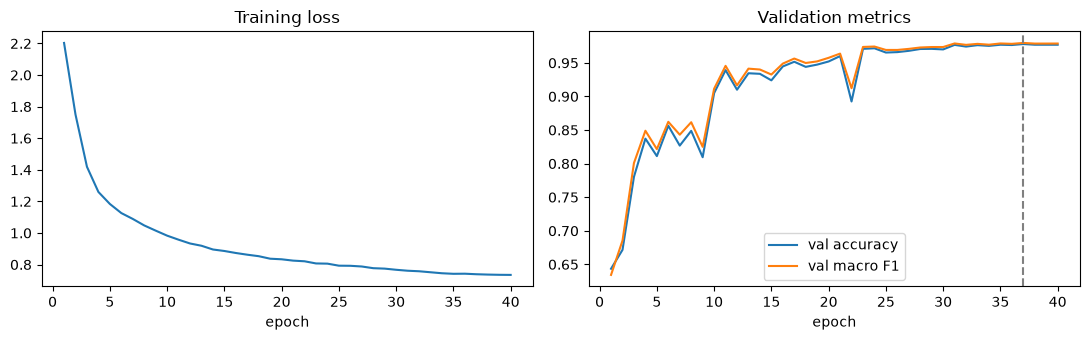

,model,val accuracy,val macro F1
0,Most frequent class,0.1537,0.0222
1,Average spectrum + logistic regression,0.6283,0.6470
2,CNN from scratch,0.9780,0.9797


In [12]:
curves = pd.DataFrame(history).set_index("epoch")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
curves["train loss"].plot(ax=axes[0], title="Training loss")
curves[["val accuracy", "val macro F1"]].plot(ax=axes[1], title="Validation metrics")
axes[1].axvline(best_epoch, color="gray", linestyle="--")
plt.tight_layout()
plt.show()
val_cnn = predict_proba(model, A_val).argmax(axis=1)
display(pd.concat([baselines, pd.DataFrame([{
    "model": "CNN from scratch",
    "val accuracy": metrics.accuracy_score(y_val, val_cnn),
    "val macro F1": metrics.f1_score(y_val, val_cnn, average="macro")}]).round(4)], ignore_index=True))

## 5. Evaluation

The chosen network is evaluated **once** on the official test list (speakers never heard in training), plus silence clips, with the unknown words subsampled as in training.

In [13]:
test_proba = predict_proba(model, A_test)
test_pred = test_proba.argmax(axis=1)
digit_mask = np.isin(test_pred, range(10))
test_metrics = {
    "accuracy": metrics.accuracy_score(y_test, test_pred),
    "f1_macro": metrics.f1_score(y_test, test_pred, average="macro"),
    "precision_macro": metrics.precision_score(y_test, test_pred, average="macro"),
    "recall_macro": metrics.recall_score(y_test, test_pred, average="macro"),
    # Of the clips detected as a digit, how many were that digit.
    "digit_precision": float((test_pred[digit_mask] == y_test[digit_mask]).mean()),
    # Unknown words or silence taken for a command.
    "false_command_rate": float(digit_mask[y_test >= 10].mean()),
}
print(metrics.classification_report(y_test, test_pred, target_names=CLASSES, digits=3))
test_summary = summary_model.predict(summary_features(A_test))
test_table = pd.DataFrame([
    {"model": "Most frequent class", "accuracy": metrics.accuracy_score(y_test, np.full_like(y_test, majority)),
     "macro F1": metrics.f1_score(y_test, np.full_like(y_test, majority), average="macro")},
    {"model": "Average spectrum + logistic regression", "accuracy": metrics.accuracy_score(y_test, test_summary),
     "macro F1": metrics.f1_score(y_test, test_summary, average="macro")},
    {"model": "CNN from scratch (ours)", "accuracy": test_metrics["accuracy"], "macro F1": test_metrics["f1_macro"]},
]).round(4)
display(test_table)
print({k: round(v, 4) for k, v in test_metrics.items()})

              precision    recall  f1-score   support

        zero      0.983     0.981     0.982       418
         one      0.985     0.957     0.971       399
         two      0.977     0.983     0.980       424
       three      0.980     0.990     0.985       405
        four      0.953     0.973     0.963       400
        five      0.984     0.984     0.984       445
         six      0.985     0.995     0.990       394
       seven      0.985     0.988     0.986       406
       eight      0.988     0.983     0.985       408
        nine      0.988     0.983     0.985       408
     unknown      0.945     0.935     0.940       821
     silence      0.990     1.000     0.995       410

    accuracy                          0.976      5338
   macro avg      0.979     0.979     0.979      5338
weighted avg      0.976     0.976     0.976      5338



,model,accuracy,macro F1
0,Most frequent class,0.1538,0.0222
1,Average spectrum + logistic regression,0.6000,0.6181
2,CNN from scratch (ours),0.9760,0.9789


{'accuracy': 0.976, 'f1_macro': 0.9789, 'precision_macro': 0.9786, 'recall_macro': 0.9794, 'digit_precision': 0.9808, 'false_command_rate': 0.0414}


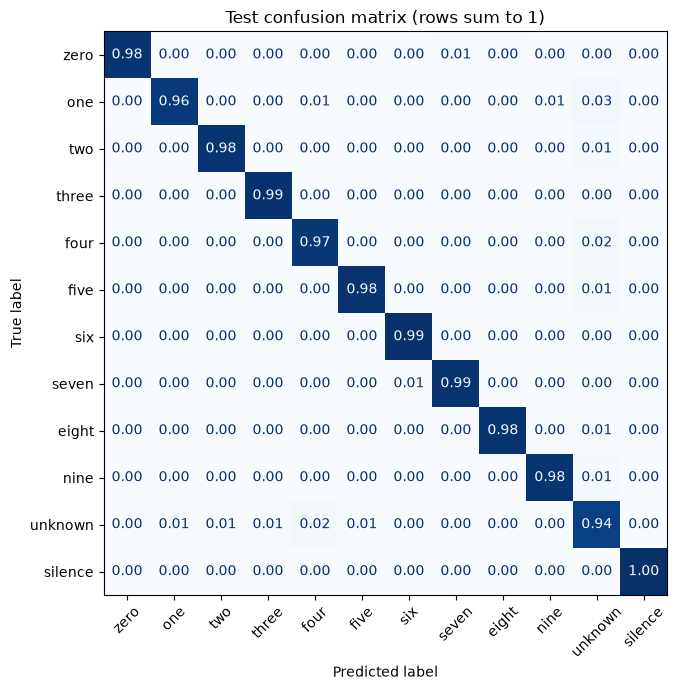

In [14]:
matrix = metrics.confusion_matrix(y_test, test_pred, normalize="true")
fig, ax = plt.subplots(figsize=(8, 7))
metrics.ConfusionMatrixDisplay(matrix, display_labels=CLASSES).plot(ax=ax, values_format=".2f", cmap="Blues", colorbar=False)
ax.set_title("Test confusion matrix (rows sum to 1)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### The procedure used in the application

In the application the user says a sentence of a few seconds ("JarvisTEC, three"), not an isolated one-second clip. The backend slides a one-second window over the recording every 100 ms, classifies every window and keeps the digit with the highest probability, provided it reaches `THRESHOLD`; otherwise it answers that it did not understand. To evaluate this, test recordings are built from **test speakers only**: an unknown word (standing in for the wake word, which is not in the dataset), a pause, a digit and background noise, about 2.5 seconds in total; and recordings with only unknown words, where nothing should be detected.

In [15]:
THRESHOLD = 0.7
STEP = SAMPLE_RATE // 10


def detect_digit(net, audio_int16):
    """Most confident digit over 1 s windows every 100 ms, or None.

    Same procedure as the backend (backend/services/speech_service.py).
    """
    audio = audio_int16
    if len(audio) < CLIP_SAMPLES:
        audio = np.pad(audio, (0, CLIP_SAMPLES - len(audio)))
    starts = range(0, len(audio) - CLIP_SAMPLES + 1, STEP)
    windows = np.stack([audio[s:s + CLIP_SAMPLES] for s in starts])
    proba = predict_proba(net, windows)
    digit_proba = proba[:, :10]
    window, digit = np.unravel_index(digit_proba.argmax(), digit_proba.shape)
    best = digit_proba[window, digit]
    return (int(digit), float(best)) if best >= THRESHOLD else (None, float(best))


def trim(clip):
    energy = np.abs(clip.astype(np.float32))
    loud = np.flatnonzero(energy > energy.max() * 0.1)
    return clip[max(loud[0] - 1600, 0):loud[-1] + 1600] if len(loud) else clip


test_rows = files[files.split == "test"].reset_index(drop=True)
digit_rows = test_rows[test_rows.word.isin(DIGITS)]
other_rows = test_rows[~test_rows.word.isin(DIGITS)]
sim_rng = np.random.default_rng(SEED)
results = []
for trial in range(600):
    command = trial < 400
    first = trim(read_clip(other_rows.path.iloc[sim_rng.integers(len(other_rows))]))
    second_row = (digit_rows if command else other_rows).iloc[sim_rng.integers(len(digit_rows if command else other_rows))]
    second = trim(read_clip(second_row.path))
    gap = np.zeros(int(sim_rng.uniform(0.15, 0.4) * SAMPLE_RATE), np.int16)
    audio = np.concatenate([gap, first, gap, second, gap]).astype(np.float32)
    noise = noises[sim_rng.integers(len(noises))]
    begin = sim_rng.integers(len(noise) - len(audio))
    audio = audio + noise[begin:begin + len(audio)] * 32767 * sim_rng.uniform(0, 0.05)
    digit, confidence = detect_digit(model, np.clip(audio, -32768, 32767).astype(np.int16))
    truth = DIGITS.index(second_row.word) if command else None
    results.append({"has command": command, "truth": truth, "detected": digit, "correct": digit == truth})
results = pd.DataFrame(results)
commands = results[results["has command"]]
others = results[~results["has command"]]
sentence_metrics = {
    "commands_correct": float(commands.correct.mean()),
    "commands_missed": float(commands.detected.isna().mean()),
    "commands_wrong_digit": float((commands.detected.notna() & ~commands.correct).mean()),
    "false_commands_without_digit": float(others.detected.notna().mean()),
}
display(pd.Series(sentence_metrics).round(3).rename("share of recordings"))

commands_correct                0.890
commands_missed                 0.102
commands_wrong_digit            0.008
false_commands_without_digit    0.065
Name: share of recordings, dtype: float64

## Export for the backend

In [16]:
model.eval().cpu()
example = torch.zeros(1, 1, N_MELS, 1 + (CLIP_SAMPLES - WINDOW) // HOP)
onnx_path = ARTIFACTS / f"{MODEL_NAME}.onnx"
torch.onnx.export(model, example, onnx_path, input_names=["log_mel"],
                  output_names=["logits"], dynamo=False, opset_version=13)

import cv2

net = cv2.dnn.readNetFromONNX(str(onnx_path))
clips = A_test[:32].astype(np.float32) / 32768
inputs = np.stack([(log_mel(c) - FEATURE_MEAN) / FEATURE_STD for c in clips])[:, None].astype(np.float32)
with torch.no_grad():
    expected = model(torch.from_numpy(inputs)).numpy()
got = []
for x in inputs:
    net.setInput(x[None])
    got.append(net.forward().ravel())
difference = np.abs(np.array(got) - expected).max()
print(f"Largest difference PyTorch vs OpenCV: {difference:.2e}")
assert difference < 1e-3
model.to(DEVICE)

meta = {
    "model": "KeywordCNN (trained from scratch)",
    "dataset": "Speech Commands v0.02 (Warden, 2018), CC BY 4.0",
    "classes": CLASSES,
    "features": {"sample_rate": SAMPLE_RATE, "clip_samples": CLIP_SAMPLES, "window": WINDOW,
                 "hop": HOP, "n_fft": N_FFT, "n_mels": N_MELS, "mel_low_hz": 20,
                 "mean": FEATURE_MEAN, "std": FEATURE_STD},
    "detection": {"threshold": THRESHOLD, "step_samples": STEP},
    "parameters": parameters,
    "hyperparameters": {"epochs": EPOCHS, "best_epoch": best_epoch, "batch_size": BATCH_SIZE,
                        "learning_rate": LEARNING_RATE, "weight_decay": WEIGHT_DECAY,
                        "label_smoothing": 0.1, "optimizer": "AdamW + OneCycleLR", "seed": SEED},
    "validation_accuracy": round(best_acc, 4),
    "test_metrics": {k: round(float(v), 4) for k, v in test_metrics.items()},
    "test_comparison": test_table.to_dict(orient="records"),
    "sentence_test": {k: round(v, 4) for k, v in sentence_metrics.items()},
    "torch_version": torch.__version__,
}
(ARTIFACTS / f"{MODEL_NAME}.meta.json").write_text(json.dumps(meta, indent=2))
print(f"Saved {onnx_path.name} ({onnx_path.stat().st_size / 1e6:.1f} MB) and {MODEL_NAME}.meta.json")

Largest difference PyTorch vs OpenCV: 2.38e-06
Saved speech_commands.onnx (3.9 MB) and speech_commands.meta.json


## 6. Conclusion

The keyword spotter trained from scratch recognizes the 12 classes with a **test accuracy of 0.976 and a macro F1 of 0.979** on speakers it never heard, far above the most frequent class (0.154 / 0.022) and the average-spectrum logistic regression (0.600 / 0.618): the order of the sounds in time, which only the convolutional network sees, is what separates the words. Every digit reaches an F1 between 0.96 and 0.99; the hardest class is "unknown" (0.94), because some of the other words sound like digits ("tree" and "three"). When the network detects a digit it is right 98 % of the time, and 4 % of the unknown words and silence clips are taken for a digit.

**The application procedure** (a one-second window sliding over a 2.5-second recording with a leading word, pauses and background noise) recognizes the right digit in **89 %** of the simulated commands, misses it in 10 % (the user is asked to repeat) and picks a wrong digit in under 1 %; 6.5 % of recordings without any digit trigger a command. A separate check with a voice the network never heard (the Windows "Microsoft David" and "Zira" synthetic voices saying "Jarvis Tec, *number*") recognized all 20 numbers and ignored both sentences without a number.

**Limitations:**
- It is a keyword spotter, not a speech-to-text system: it understands only the ten digits in English, so a command is a number ("JarvisTEC, three") instead of a sentence, and data inside the command ("red wine") or Spanish commands need the other engines (Vosk or the browser), which remain the default; this network is used only when `SPEECH_PROVIDER=scratch` is set.
- Speech Commands are short, isolated words recorded by volunteers; long sentences, strong accents or far-field microphones were not part of the training, and the wake word is not recognized (any word before the number is ignored).
- The 0.7 threshold balances missed commands against false ones; it was set by hand, not tuned.

**Future improvements:** record the JarvisTEC phrases with several people to train a real command vocabulary, add a wake-word class, and tune the threshold on validation recordings.

### References
- Warden, P. (2018). Speech Commands: A dataset for limited-vocabulary speech recognition. arXiv:1804.03209.
- Sainath, T. N., & Parada, C. (2015). Convolutional neural networks for small-footprint keyword spotting. Interspeech 2015.
- Park, D. S., et al. (2019). SpecAugment: A simple data augmentation method for automatic speech recognition. Interspeech 2019.
- Ioffe, S., & Szegedy, C. (2015). Batch normalization. ICML 2015.
- Loshchilov, I., & Hutter, F. (2019). Decoupled weight decay regularization. ICLR 2019.
- Smith, L. N., & Topin, N. (2019). Super-convergence: Very fast training of neural networks using large learning rates. SPIE 11006.